In [ ]:
import pandas as pd

# 1. Carregar a base de dados em CSV
df_br = pd.read_csv('focos_mensal_queimadas_BR.csv')

# 2. Exibir as 5 primeiras linhas
print("Primeiras linhas do dataset do Brasil:")
display(df_br.head())

# 3. Filtrar e verificar os dados do Amazonas via Python
df_am = df_br[df_br['estado'].str.upper() == 'AMAZONAS']
print(f"\nTotal de focos no Brasil: {len(df_br)}")
print(f"Total de focos no Amazonas (via Python): {len(df_am)}")

Primeiras linhas do dataset do Brasil:


,id,lat,lon,data_hora_gmt,satelite,municipio,estado,pais,municipio_id,estado_id,pais_id,numero_dias_sem_chuva,precipitacao,risco_fogo,bioma,frp
0,4107e0d9-4582-35ac-b76b-39a4891552ae,-18.0414,-51.3317,2026-08-01 00:00:00,GOES-19,JATAÍ,GOIÁS,Brasil,5211909,52,33,7.0,0.0,1.00,Cerrado,82.4
1,112191a8-1320-35af-bf83-a32cf4f28b1e,-3.0612,-39.9346,2026-08-01 00:00:00,GOES-19,ITAREMA,CEARÁ,Brasil,2306553,23,33,9.0,0.0,0.63,Caatinga,77.5
2,6dd9eab1-6df4-3056-a266-5f65c2c9cfb7,-7.6505,-45.0624,2026-08-01 00:00:00,GOES-19,RIBEIRO GONÇALVES,PIAUÍ,Brasil,2208908,22,33,17.0,0.0,1.00,Cerrado,67.8
3,9397d27a-9b37-3537-a27f-bb654e94ffb6,-18.0419,-51.3097,2026-08-01 00:00:00,GOES-19,JATAÍ,GOIÁS,Brasil,5211909,52,33,7.0,0.0,1.00,Cerrado,271.7
4,0b9491b5-ce40-3247-8e57-c86444c6e0f2,-18.0619,-51.3063,2026-08-01 00:00:00,GOES-19,JATAÍ,GOIÁS,Brasil,5211909,52,33,8.0,0.0,1.00,Cerrado,103.4



Total de focos no Brasil: 651243
Total de focos no Amazonas (via Python): 89048


In [4]:
import geopandas as gpd

# Ler a camada exportada do QGIS
gdf_am = gpd.read_file('focos_queimadas_mensal_AM.gpkg')

print(f"Total de registros na camada GeoPackage do AM: {len(gdf_am)}")
display(gdf_am.head())

Total de registros na camada GeoPackage do AM: 89048


,id,lat,lon,data_hora_gmt,satelite,municipio,estado,pais,municipio_id,estado_id,pais_id,numero_dias_sem_chuva,precipitacao,risco_fogo,bioma,frp,geometry
0,5d1018c7-dbfc-3adf-af31-76d1d38567bb,-2.81749,-60.00382,2026-08-01 04:55:00,NPP-375D,MANAUS,AMAZONAS,Brasil,1302603,13,33,9.0,0.00,0.35,Amazônia,1.4,POINT (-60.00382 -2.81749)
1,7783d1c5-4597-3be8-be5a-13bb0f011ead,-2.81879,-60.00368,2026-08-01 05:14:00,NOAA-20,MANAUS,AMAZONAS,Brasil,1302603,13,33,9.0,0.00,0.35,Amazônia,1.8,POINT (-60.00368 -2.81879)
2,7afb52b6-2f7f-3da2-a0ac-4fb58d2d4397,-9.08158,-65.37730,2026-08-01 05:16:00,NOAA-20,LÁBREA,AMAZONAS,Brasil,1302405,13,33,0.0,0.83,0.29,Amazônia,2.2,POINT (-65.3773 -9.08158)
3,22ac95ca-1f17-345d-8bbf-5441a091b135,-3.75263,-59.26872,2026-08-01 05:16:00,NOAA-20,AUTAZES,AMAZONAS,Brasil,1300300,13,33,4.0,1.41,0.25,Amazônia,1.4,POINT (-59.26872 -3.75263)
4,1b90af75-bb0a-389e-92fa-842c46805b0b,-7.87058,-61.68662,2026-08-01 05:16:00,NOAA-20,MANICORÉ,AMAZONAS,Brasil,1302702,13,33,1.0,3.64,0.69,Amazônia,1.0,POINT (-61.68662 -7.87058)


## Validação de Bases de Dados Complementares (Etapas 5 e 6)

1. **PRODES (INPE)**
   - **Link:** https://terrabrasilis.dpi.inpe.br/
   - **O que oferece:** Mapeamento anual de desmatamento por corte raso na Amazônia Legal.
   - **Recorte do AM:** Sim, cobre 100% do estado.
   - **Uso no projeto:** Identificar se o foco de calor ocorreu em área recém-desmatada ou vegetação nativa.

2. **MapBiomas**
   - **Link:** https://mapbiomas.org/
   - **O que oferece:** Séries históricas de uso e cobertura da terra (floresta, pastagem, agricultura).
   - **Recorte do AM:** Sim, dados disponíveis para todo o território estadual.
   - **Uso no projeto:** Mapear a classe de vegetação/uso do solo onde o fogo foi detectado.

3. **Sentinel-2 (ESA)**
   - **Link:** https://browser.dataspace.copernicus.eu/
   - **O que oferece:** Imagens ópticas de alta resolução (10-20m).
   - **Recorte do AM:** Sim, cobertura global por órbitas diárias/semanais.
   - **Uso no projeto:** Calcular índices espectrais (NDVI e NBR) para severidade do fogo.

4. **Elevação (SRTM / TOPODATA / ALOS PALSAR)**
   - **Link:** http://www.webmapit.com.br/inpe/topodata/
   - **O que oferece:** Modelo Digital de Elevação (MDE), declividade e orientação de rampa.
   - **Recorte do AM:** Sim, cobertura completa do estado.
   - **Uso no projeto:** Analisar se o relevo influencia na propagação das queimadas.

5. **Clima / Meteorologia (INMET / ERA5)**
   - **Link:** https://bdmep.inmet.gov.br/
   - **O que oferece:** Precipitação, umidade e temperatura.
   - **Recorte do AM:** Sim, estações físicas e dados de reanálise de grade.
   - **Uso no projeto:** Correlacionar dias sem chuva e déficit hídrico com ocorrência de focos.

In [6]:
import os
import urllib.request
import geopandas as gpd

# 1. Definir URL oficial do IBGE e nome do arquivo local
url_ibge_am = "https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2022/UFs/AM/AM_Municipios_2022.zip"
zip_local = "AM_Municipios_2022.zip"

# 2. Fazer o download simulando um navegador para evitar bloqueio do IBGE
if not os.path.exists(zip_local):
    print("Baixando limites dos municípios do AM do IBGE...")
    req = urllib.request.Request(url_ibge_am, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response, open(zip_local, 'wb') as out_file:
        out_file.write(response.read())
    print("Download concluído com sucesso!")
else:
    print("O arquivo zip já existe na pasta local.")

# 3. Carregar o arquivo ZIP diretamente no GeoPandas
gdf_municipios = gpd.read_file(zip_local)

# 4. Exibir os 5 primeiros municípios
print(f"Total de municípios carregados: {len(gdf_municipios)}")
display(gdf_municipios[['CD_MUN', 'NM_MUN', 'geometry']].head())

Baixando limites dos municípios do AM do IBGE...
Download concluído com sucesso!
Total de municípios carregados: 62


,CD_MUN,NM_MUN,geometry
0,1300029,Alvarães,"POLYGON ((-64.71229 -3.27608, -64.7162 -3.2769..."
1,1300060,Amaturá,"POLYGON ((-67.94285 -3.32959, -67.87343 -3.332..."
2,1300086,Anamã,"POLYGON ((-61.51715 -3.6848, -61.54102 -3.6842..."
3,1300102,Anori,"POLYGON ((-61.86552 -3.97394, -61.88421 -3.965..."
4,1300144,Apuí,"POLYGON ((-60.07249 -8.80016, -60.08515 -8.800..."


--- TOP 10 MUNICÍPIOS COM MAIS FOCOS DE CALOR NO AM ---
municipio
APUÍ             38970
NOVO ARIPUANÃ     9426
MAUÉS             8338
LÁBREA            5642
MANICORÉ          5305
MANACAPURU        2902
HUMAITÁ           1873
AUTAZES           1845
CANUTAMA          1415
CAAPIRANGA        1179
Name: count, dtype: int64


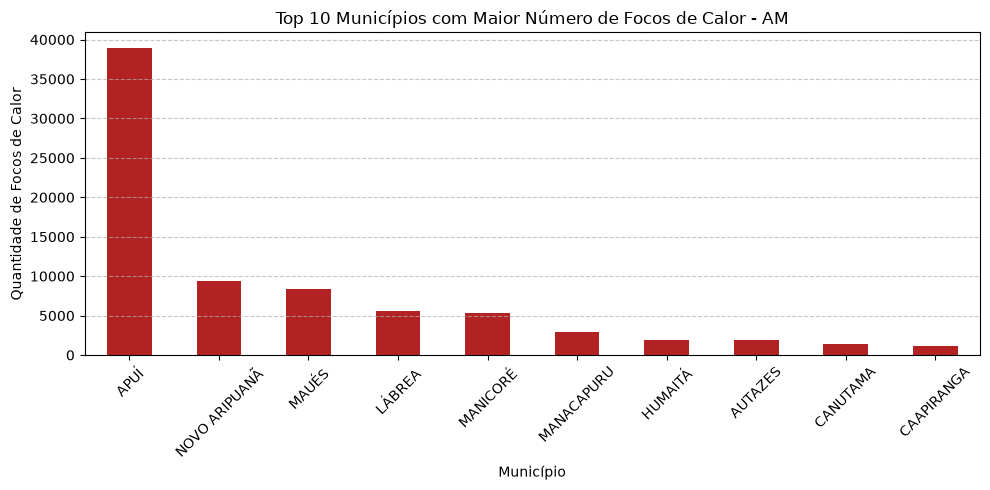

In [9]:
import matplotlib.pyplot as plt

# 1. Agrupar focos de calor por município
top10_municipios = gdf_am['municipio'].value_counts().head(10)

print("--- TOP 10 MUNICÍPIOS COM MAIS FOCOS DE CALOR NO AM ---")
print(top10_municipios)

# 2. Criar um gráfico de barras para visualizar
plt.figure(figsize=(10, 5))
top10_municipios.plot(kind='bar', color='firebrick')

plt.title('Top 10 Municípios com Maior Número de Focos de Calor - AM')
plt.xlabel('Município')
plt.ylabel('Quantidade de Focos de Calor')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Exibir o gráfico
plt.show()

In [2]:
import os
import urllib.request
import geopandas as gpd

# 1. Carregar os Focos de Calor do Amazonas (GeoPackage)
gdf_am = gpd.read_file('focos_queimadas_mensal_AM.gpkg')

# 2. Carregar a Malha de Municípios do IBGE (Baixar se não existir localmente)
zip_local = "AM_Municipios_2022.zip"
if not os.path.exists(zip_local):
    url_ibge_am = "https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2022/UFs/AM/AM_Municipios_2022.zip"
    req = urllib.request.Request(url_ibge_am, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response, open(zip_local, 'wb') as out_file:
        out_file.write(response.read())

gdf_municipios = gpd.read_file(zip_local)

# 3. Validar e Padronizar o Sistema de Coordenadas (CRS)
if gdf_am.crs != gdf_municipios.crs:
    gdf_municipios = gdf_municipios.to_crs(gdf_am.crs)

# 4. Executar a Junção Espacial (Spatial Join)
focos_com_municipio = gpd.sjoin(gdf_am, gdf_municipios, how="inner", predicate="intersects")

# 5. Exibir o resultado validado
print(f"Total de focos validados dentro do território do AM: {len(focos_com_municipio)}")
display(focos_com_municipio[['NM_MUN', 'data_hora_gmt', 'satelite', 'geometry']].head())

Total de focos validados dentro do território do AM: 89044


,NM_MUN,data_hora_gmt,satelite,geometry
0,Manaus,2026-08-01 04:55:00,NPP-375D,POINT (-60.00382 -2.81749)
1,Manaus,2026-08-01 05:14:00,NOAA-20,POINT (-60.00368 -2.81879)
2,Lábrea,2026-08-01 05:16:00,NOAA-20,POINT (-65.3773 -9.08158)
3,Autazes,2026-08-01 05:16:00,NOAA-20,POINT (-59.26872 -3.75263)
4,Manicoré,2026-08-01 05:16:00,NOAA-20,POINT (-61.68662 -7.87058)


--- TOP 10 MUNICÍPIOS LÍDERES EM QUEIMADAS NO AM (DADOS VALIDADOS) ---
NM_MUN
Apuí             38970
Novo Aripuanã     9426
Maués             8338
Lábrea            5642
Manicoré          5305
Manacapuru        2902
Humaitá           1873
Autazes           1845
Canutama          1415
Caapiranga        1179
Name: count, dtype: int64


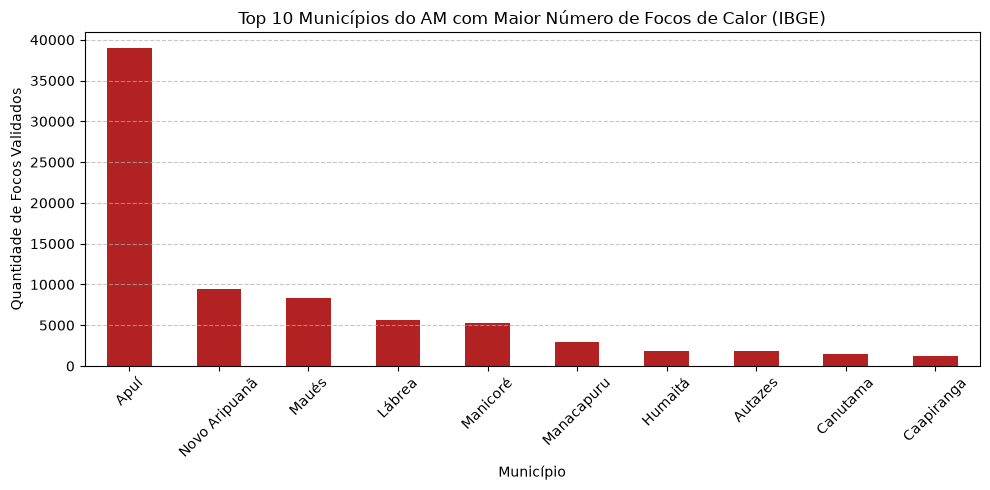

In [3]:
import matplotlib.pyplot as plt

# 1. Agrupar os focos validados pela malha do IBGE e pegar os 10 maiores
top10_ibge = focos_com_municipio['NM_MUN'].value_counts().head(10)

print("--- TOP 10 MUNICÍPIOS LÍDERES EM QUEIMADAS NO AM (DADOS VALIDADOS) ---")
print(top10_ibge)

# 2. Gerar o gráfico de barras
plt.figure(figsize=(10, 5))
top10_ibge.plot(kind='bar', color='firebrick')

plt.title('Top 10 Municípios do AM com Maior Número de Focos de Calor (IBGE)')
plt.xlabel('Município')
plt.ylabel('Quantidade de Focos Validados')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

In [4]:
# Exportar o GeoDataFrame com a junção espacial realizada
focos_com_municipio.to_file("focos_queimadas_AM_validados_ibge.gpkg", driver="GPKG")

print("Ficheiro 'focos_queimadas_AM_validados_ibge.gpkg' salvo com sucesso!")

Ficheiro 'focos_queimadas_AM_validados_ibge.gpkg' salvo com sucesso!


In [5]:
# Reprojetar para metros (SIRGAS 2000 / Brasil Polyconic - EPSG:5880)
focos_com_municipio_m = focos_com_municipio.to_crs(epsg=5880)

# Exportar versão projetada em metros
focos_com_municipio_m.to_file("focos_queimadas_AM_validados_utm.gpkg", driver="GPKG")
print("Arquivo reprojectado salvo com sucesso!")

Arquivo reprojectado salvo com sucesso!
